[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SURIAPRAKASH1/reinforcement_learning/blob/main/notebooks/tabular-methods.ipynb)

In [ ]:
import torch
from torch import tensor
import gymnasium as gym

import numpy as np
import random
import math
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("current device -->", DEVICE)

current device --> cpu


# Multi-Armed Bandit:
- Multi-Armed Bandit: A simple version of reinforcement learning problem.
   - Don't confuse Reinforcement Learning **Problem** with **Methods**.
     - For e.g, **Multi-Armed Bandit** is a problem and **Sample Average, Incremental Compute** these are action-values methods to solve that problem.
- Each timestep-$t$ we have Arms (actions or chocies) that can be taken.
- Have to take the optimal action at each timestep-$t$. And also have to balance **Exploration and Exploitation**.

## 10-Armed Testbet:
- 10-Armed Testbet is *Test Set* with *k = 10 (10 actions at each t)* to evaluate any bandit algo and behaviour of Learning Algorithm; Sample average method, Incremental Compute action-value methods can be evaluated by this Testbet.
- For each timestep t, The true value $q_{*}(A = a)$ is selected from **Normal Guassian Distribution** with mean = 0 and variance = 1.
- The Actuall Reward $R_{t}$ selected from **Normal Distribution** with mean = $q_{*}(A = a)$ and variance = 1.
- **Simulating True action-values** $q_{*}(A = a)$ in statistics way.

In [ ]:
# k-armed bandit
k = 10
time_steps = int(1e+4)
eps = 0.1
alpha = 0.1
# initial true action-values for all a are equall to 0
q_true = np.zeros(k)
# initial estimated action-values for all a are equall to 0
Q_sample = np.zeros(k)  # -> to hold action-values by sample average method
Q_const = np.zeros(k)   # -> to hold action-values by const step with Incremental compute
# How many times each action a is taken?
N_counts = np.zeros(k, dtype= np.long)

# rewards stats; actually ain't take mean; What's the point to mean for scaler
avg_reward_sample = np.zeros(time_steps)
opt_action_pct_sample = np.zeros(time_steps)
avg_reward_const = np.zeros(time_steps)
opt_action_pct_const = np.zeros(time_steps)

def bandit(q_true, A):
    "Reward for taken action"
    reward = np.random.normal(loc = q_true[A], scale= 1.0)
    return reward

def sample_average(Q_sample, A, R, N_counts):
    "Calculates New estimate value for action by sample average"
    new_estimated_value = Q_sample[A] + (R - Q_sample[A]) / N_counts[A]
    return new_estimated_value

def incremental_compute(Q_const, A, R):
    "Calculates New estimate value for action by incremental compute method"
    new_estimated_value = Q_const[A] + alpha * (R - Q_const[A])
    return new_estimated_value

for t in range(time_steps):

    # -----------------------------
    # Method 1: Incremental Compute
    # ----------------------------

    # Take greedy action - Exploitatoin
    if np.random.rand() < (1 - eps):
        action_const = np.random.choice(np.flatnonzero(Q_const == Q_const.max())).item() # breaks ties randomly
    # Take eps greedy action - Exploration
    else:
        action_const = np.random.randint(k)

    # reward for taken action
    reward_const = bandit(q_true, action_const)
    avg_reward_const[t] = reward_const
    Q_const[action_const] = incremental_compute(Q_const, action_const, reward_const)
    optimal_action = q_true.argmax()
    opt_action_pct_const[t] = (action_const == optimal_action) * 100.0

    # ------------------------
    # Method 2: Sample Average
    # ------------------------

    if np.random.rand() < (1 - eps):
        action_sample = np.random.choice(np.flatnonzero(Q_sample == Q_sample.max())).item()
    else:
        action_sample = np.random.randint(k)

    reward_sample = bandit(q_true, action_sample)
    avg_reward_sample[t] = reward_sample
    N_counts[action_sample] += 1
    Q_sample[action_sample] = sample_average(Q_sample, action_sample, reward_sample, N_counts)
    opt_action_pct_sample[t] = (action_sample == optimal_action)* 100.0
    # Each t-timesteps incrementing true action-values with mean = 0, variance = 0.01
    q_true += np.random.normal(loc= 0.0, scale= 0.01, size= q_true.shape)


In [ ]:
def ema_for_lot(samples, consts, alphaa = 0.999):
    """Applys Exponentially Weighted Moving Average"""
    ema_consts = []
    ema_samples = []
    const_v0 = 0
    sample_v0 = 0

    for const, sample in zip(consts, samples):
        sample_v =  alphaa * sample_v0 + (1 - alphaa) * sample
        const_v = alphaa * const_v0 + (1 - alphaa) * const
        ema_consts.append(const_v)
        ema_samples.append(sample_v)
        const_v0 = const_v
        sample_v0 = sample_v

    return ema_samples, ema_consts

In [ ]:
def average_reward_vs_time(avg_reward_sample, avg_reward_const):
    # Average reward vs time
    plt.figure(figsize=(10,5))
    plt.plot(avg_reward_sample, label='Sample-average (1/N)')
    plt.plot(avg_reward_const, label='Constant step-size (alpha=0.1)')
    plt.xlabel('Steps')
    plt.ylabel('Average reward')
    plt.title('Average reward vs steps (nonstationary 10-armed bandit)')
    plt.legend()
    plt.grid(True)
    plt.show()

def optimal_action_vs_time(opt_pct_sample, opt_pct_const):
    #% optimal action vs time
    plt.figure(figsize=(10,5))
    plt.plot(opt_pct_sample, label='Sample-average (1/N)')
    plt.plot(opt_pct_const, label='Constant step-size (alpha=0.1)')
    plt.xlabel('Steps')
    plt.ylabel('% Optimal action')
    plt.title('% optimal action vs steps (nonstationary 10-armed bandit)')
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
# Vectorized implementation to speed up the experiment.
import numpy as np
import matplotlib.pyplot as plt
import os

np.random.seed(0)

def run_nonstationary_vectorized(k=10, time_steps=10000, num_runs=200, eps=0.1, alpha=0.1):
    # arrays per run
    q_true = np.zeros((num_runs, k))     # true action values for each run
    Q_sample = np.zeros((num_runs, k))   # estimates for sample-average
    N_sample = np.zeros((num_runs, k))   # counts for sample-average
    Q_const = np.zeros((num_runs, k))    # estimates for constant-step-size

    avg_reward_sample = np.zeros(time_steps)
    opt_action_pct_sample = np.zeros(time_steps)
    avg_reward_const = np.zeros(time_steps)
    opt_action_pct_const = np.zeros(time_steps)

    run_indices = np.arange(num_runs)

    for t in range(time_steps):
        # determine greedy actions (with tiny noise to break ties randomly)
        noisy_Q_sample = Q_sample + 1e-8 * np.random.randn(*Q_sample.shape)
        greedy_sample = noisy_Q_sample.argmax(axis=1)
        explore_mask = (np.random.rand(num_runs) >= (1 - eps))
        # choose actions
        random_actions = np.random.randint(0, k, size=num_runs)
        actions_sample = np.where(explore_mask, random_actions, greedy_sample)

        # rewards for sample-average agent
        rewards_sample = np.random.normal(loc=q_true[run_indices, actions_sample], scale=1.0)
        # update counts and estimates using np.add.at for indexing increments
        # first increment counts
        np.add.at(N_sample, (run_indices, actions_sample), 1)
        # compute deltas and update Q for only the taken actions
        idx_counts = N_sample[run_indices, actions_sample]
        prev_Qs = Q_sample[run_indices, actions_sample]
        Q_sample[run_indices, actions_sample] = prev_Qs + (rewards_sample - prev_Qs) / idx_counts

        avg_reward_sample[t] = rewards_sample.mean()
        optimal_actions = q_true.argmax(axis=1)
        opt_action_pct_sample[t] = np.mean(actions_sample == optimal_actions) * 100.0

        # constant-step-size agent
        noisy_Q_const = Q_const + 1e-8 * np.random.randn(*Q_const.shape)
        greedy_const = noisy_Q_const.argmax(axis=1)
        explore_mask_const = (np.random.rand(num_runs) >= (1 - eps))
        random_actions_const = np.random.randint(0, k, size=num_runs)
        actions_const = np.where(explore_mask_const, random_actions_const, greedy_const)

        rewards_const = np.random.normal(loc=q_true[run_indices, actions_const], scale=1.0)
        prev_Qc = Q_const[run_indices, actions_const]
        Q_const[run_indices, actions_const] = prev_Qc + alpha * (rewards_const - prev_Qc)

        avg_reward_const[t] = rewards_const.mean()
        opt_action_pct_const[t] = np.mean(actions_const == optimal_actions) * 100.0

        # random walk on true action values for each run
        q_true += np.random.normal(loc=0.0, scale=0.01, size=q_true.shape)

    return avg_reward_sample, opt_action_pct_sample, avg_reward_const, opt_action_pct_const

# Run
k = 10
time_steps = 10000
num_runs = 2000  # increase to 2000 if you want smoother curves
eps = 0.1
alpha = 0.1

avg_reward_sample, opt_pct_sample, avg_reward_const, opt_pct_const = run_nonstationary_vectorized(
    k=k, time_steps=time_steps, num_runs=num_runs, eps=eps, alpha=alpha)

# Plot 1:
average_reward_vs_time(avg_reward_sample, avg_reward_const)

# Plot 2:
optimal_action_vs_time(opt_pct_sample, opt_pct_const)

# Save result arrays for later
outdir = '/mnt/data/bandit_results_vectorized'
os.makedirs(outdir, exist_ok=True)
np.save(os.path.join(outdir, 'avg_reward_sample.npy'), avg_reward_sample)
np.save(os.path.join(outdir, 'avg_reward_const.npy'), avg_reward_const)
np.save(os.path.join(outdir, 'opt_pct_sample.npy'), opt_pct_sample)
np.save(os.path.join(outdir, 'opt_pct_const.npy'), opt_pct_const)

print(f"Done. num_runs={num_runs}, time_steps={time_steps}. Results saved to {outdir}")


## UCB - Upper Confidence Bound:
 - UCB is a action selection method (not a action-value Estimation methods like Sample Average, Incremental Compute).
 - $\epsilon-greedy$ for action selection randomly selects action without ever considering those random actions potential to become a maximal.
 - Unlike $\epsilon-greedy$ UCB gives preference to actions by thier potential.

   $\hspace{5em} A_{t} = argmax_{a}[Q_{t}(a) + c \sqrt log(t)/N_{t}(a)]$
  
   - Here sqrt term $\sqrt log(t)/N_t(a)$ determines uncertainty. Intuitively $N_{t}(a)$, if action selected more times then uncertainty level get decreased (cause $N_{t}(a)$ in denominator). In other hand $t$ get increased but action selected rarely then uncertaintly level get increased.
   - $c$ confidence level $c > 0$ controls exploratoin.
  

In [ ]:
def upper_confidence_bound(k: int,
                           num_runs: int,
                           time_steps: int,
                           alpha: float,
                           c: float,):

    q_true = torch.randn(num_runs, k)
    Q_const = torch.empty_like(q_true).fill_(0)
    counts = torch.zeros(num_runs, k, dtype=torch.long)

    avg_reward_const = torch.zeros(1, time_steps)
    opt_action_const = torch.zeros(1, time_steps)

    tasks = torch.arange(0, num_runs)

    for t in range(time_steps):

        # Phase 1: UCB Action Selection
        uncertainty_explore =  c * torch.sqrt(torch.log(torch.tensor(t)).div(counts))
        action_const = torch.argmax(Q_const + torch.where(torch.isinf(uncertainty_explore), Q_const, uncertainty_explore), dim = 1, keepdim= True)

        rewards_const = torch.normal(mean = q_true.gather(dim = 1, index= action_const), std = 1.0 )
        Q_const[tasks, action_const.flatten()] = Q_const.gather(dim = 1, index = action_const).flatten()  + alpha * (rewards_const - Q_const.gather(dim = 1, index = action_const)).flatten()

        counts[tasks, action_const.flatten()] += 1
        avg_reward_const[0, t] = rewards_const.mean()
        opt_action_const[0, t] = (q_true.argmax(dim = 1, keepdim= True) == action_const).float().mean() * 100
        q_true += torch.normal(0.0, 0.01, q_true.shape)

    return avg_reward_const, opt_action_const

In [ ]:
ucb_avg_reward, ucb_opt_action = upper_confidence_bound(k = 10, num_runs= 2000, time_steps= 1000, alpha= 1e-2, c= 2)

plt.plot(ucb_avg_reward.tolist()[0])
plt.xlabel("Time Steps")
plt.ylabel("Average Rewards")
plt.title("Average Rewards vs Time Steps for UCB")
plt.show()

plt.plot(ucb_opt_action.tolist()[0])
plt.xlabel("Time Steps")
plt.ylabel("Optimal Actions %")
plt.title("Optimal Actions vs Time Steps for UCB")
plt.show()

## Gradient Bandit Algorithm:
- Gradient Bandit Algorithm uses numerical preference to select actions.**Higher the preference** is mostly likly that action will be selected.
- $H_{t}(a)$ defines initial *action-preference*. Initialy we set $H_{t}(a) = 0$ for all actions.

    $\hspace{5em} P{A_{t} = a} \space \dot{=} \space e^{H_{t}(a)}/ \sum_{b = 1}^{k} e^{H_{t}(b)} \space \dot{=} \space \pi_{t}(a)$  

    - $\pi_{t}(a)$ gives probability of taking action $a$ at timestep $t$. *Soft-max* used to get probabilities distribution.
- In action-values methods we use *sample average, incremental compute* to estimate action-values. But for *gradient bandit algorithms* we use **stochastic gradient ascent** like idea to update *action-preferences*.  

    $\hspace{5em} H_{t+1}(A_{t}) = H_{t}(A_{t}) + α (R_{t} - ̅R_{t}) π_{t}(A_{t})$ if $a = A_{t}$ (if action selected use this update rule)

    $\hspace{5em} H_{t+1}(a) = H_{t}(a) - α (R_{t} - ̅R_{t}) \pi_{t}(a) $, if $a \not = A_{t}$, (if not action selected use this update rule)

    - Here $\bar{R}_{t}$ defines average rewards (included or not included t) far now. $\alpha$ is step size. If current reward for action is higher than average rewards we nodge that action-preference to higher. If not then it's not optimal action to take so nodge that action-preference to lower.

     
      

In [ ]:
def gradient_bandit_alogorithm(
        k: int,
        num_runs: int,
        time_steps: int,
        alpha: float
        ):

    # True action values drawn from gaussian with mean = 4.0, std = 1.0
    q_true = torch.normal(mean = 4.0, std = 1.0, size = (num_runs, k))
    # Average reward - For baseline to compare against
    average_rewards = torch.zeros(num_runs)
    # Initial actions-preference
    action_pref = torch.zeros(num_runs, k)

    tasks = torch.arange(0, num_runs)
    opt_avg_actions = torch.zeros(time_steps)

    for t in range(time_steps):
        # --------------------
        # A. Action - Selection
        # --------------------
        actions_dist = action_pref.softmax(dim = 1)
        actions = torch.multinomial(actions_dist, 1)

        # ----------------------------
        # B. Reward For Selected Action
        # ----------------------------
        rewards = torch.normal(mean = q_true.gather(dim = 1, index= actions), std = 1.0).flatten()

        # ---------------------------
        # C. Update Action-Preferences
        # ----------------------------
        if t == 0: # Use t==0 for the first timestep
            average_rewards = rewards
        else: # Update average rewards incrementally
            average_rewards = average_rewards + alpha * (rewards - average_rewards)

        # Create a mask for selected actions
        selected_mask = torch.zeros_like(action_pref, dtype=torch.bool)
        selected_mask[tasks, actions.flatten()] = True
        unselected_mask = ~selected_mask

        # Update preference for the selected action
        action_pref[selected_mask] = action_pref[selected_mask] + alpha * (rewards - average_rewards) * (1 - actions_dist[selected_mask])

        # Update preferences for unselected actions
        action_pref[unselected_mask] = action_pref[unselected_mask] - alpha * ((rewards.unsqueeze(1) - average_rewards.unsqueeze(1)) * actions_dist)[unselected_mask]

        # ---------------------------------------------------
        # D. Take random step for True values -> Nonstationary
        # ----------------------------------------------------
        q_true += torch.normal(0.0, 0.01, q_true.shape)

        # track optimal actions
        opt_avg_actions[t]  = (q_true.argmax(dim = 1, keepdim= True) == actions).float().mean() * 100

    return opt_avg_actions

In [ ]:
opt_avg_actions = gradient_bandit_alogorithm(k = 10, num_runs= 2000, time_steps= 1000, alpha= 1e-1)

plt.figure(figsize=(10,5))
plt.plot(opt_avg_actions)
plt.xlabel('Steps')
plt.ylabel('% Optimal action')
plt.title('% optimal action vs steps (GBA nonstationary 10-armed bandit)')
plt.grid(True)
plt.show()

# Finite Markov Decision Process:
- Finite Markov Decision Process is a evalutive feedback problem just like as bandit but it also has associate aspect $-$ where different actions associate with different actions.
- FMDP's are classical formalaization of sequentail decision making $-$ where actions doesn't only affect immediate reward but also future rewards or situations.
- In bandit we estimate $q_{*}(a)$ $-$ action-values; But in FMDP we estimate $q_{*}(s, a)$ $-$ action-values on each state and $v_{*}(s)$ $-$ state-values on each state.



# Dynamic Programming:
- In general **Dynamic Programming** is a solution method to solve complex sequential problems. Dynamic Programming solves problems by first solving subproblems and combine those solutions to subproblems to solve overall problem.
- To solve problems with dynamic programming, problems have to have certain properties. Those are **Optimal Substructure**, **Overlapping Subproblems**.
- Fortunately **Markov Decision Process - MDP** have these two properties.  

## Iterative Policy Evaluation:
- DP used to compute value-function for any arbitrary policy-$π$. Actually DP estimating value-function.
- DP starting to estimates value-function by initially setting 0 to all value of state $v_{1}(s) = 0$, for $s ∈ S$. Then iteratively updating old state values by new state vlaues.

$\hspace{5em} v_{k+1}  = ∑\limits_{a} \pi(a | s) ∑\limits_{s', r} p(s', r| s, a) [r + γ v_{k}(s')]$

- It's called *iterative policy evalution* cause for each timestep, DP computes value-function initially random, if policy-$π$ makes decision based on that value-function it's completely random policy but overtime $k → ∞$ DP's estimation for $v_{k} = v_{π}$ so if now policy makes decision based on this new value-fuction $v_{k}$ is ain't a random policy no more (it's optimal policy 👍).


## Policy Iteration:
- Policy Iteration is process of evaluating any arbitrary policy-$\pi$ by estimating value-function-$v_{π}$, and making greedy policy-$π'$ by acting with respect to value-function of original policy.

$\hspace{5em} π_{0} ⟶ v_{\pi_{0}} ⟶ \pi_{1} ⟶ v_{\pi_{1}} ⟶π_{2} ⟶ ... \pi_{*}⟶v_{*}$

### Poisson Probability Distripution
- Poisson probability is a discrete probability distripution used to compute pobability of Indepentend events occuring in interval time.
- Imagine as you're owner of bakery-shop and that you know for one day average of 3 customers you're got. You what to know the probability of getting 4 or 5 or 1 or 2 or x customers per day.

$\hspace{5em} P(X=x) = \frac{λ^x e^{-λ}}{x!}$

* $X$ is random variable of taking any value $x = 0, 1, 2 ..$
* $λ$ is Expectation - Where in our example 3 average customers per day is $λ$.

- For numerical stability and vectorized to compute poisson prob we compute on log space.

$\hspace{5em} log P(X= x) = log(\frac{λ^x e^{-λ}}{x!})$

- $Log$ rules,

$\hspace{10em} log(\frac{1}{x}) = -x , \text{so} ⇒$ $log(\frac{1}{x!}) = -lgamma(x+1)) $

$\hspace{10em} log(e^{-λ}) = -λ$

$\hspace{10em} log(λ^x) = xlog(λ)$

- Numerically stable form to compute poisson probs in log space as vectorized,

$\hspace{5em} log P(X=x) = xlog(λ)-
λ-lgamma(x+1)$

- Finally take $exponential$ to recover orignal probabilities,

$\hspace{5em} P(X = x) = e^{log(P(X=x))}$

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

# PARAMETERS
MAX_CARS = 20
MAX_MOVES = 5
ACTIONS = torch.arange(-MAX_MOVES, MAX_MOVES + 1, device=device)  # shape (11,)
GAMMA = 0.9

# helper: poisson probabilities as torch vector length (MAX_CARS+1)
def poisson_probs_torch(lam, max_x=20, device=device, dtype=dtype, eps=1e-12):
    lam = torch.as_tensor(lam, device=device, dtype=dtype)
    x = torch.arange(max_x + 1, device=device, dtype=dtype)
    lam_unsq = lam.view(*( (1,) * (x.dim()) )) if lam.dim() else lam.unsqueeze(0)
    # simple scalar case: compute directly
    # Numerically stable in log-space:
    log_lam = torch.log(torch.clamp(lam, min=eps))
    log_p = x * log_lam - torch.lgamma(x + 1) - lam
    return torch.exp(log_p)  # shape (max_x+1,) for scalar lam

# Build the 4-way joint outcome probability tensor (cA, rA, cB, rB) -> shape (21,21,21,21)
def build_all_outcome_probs(customerA_lambda=3.0, customerB_lambda=4.0, returnA_lambda=3.0, returnB_lambda=2.0):
    p_cA = poisson_probs_torch(customerA_lambda)   # (21,)
    p_rA = poisson_probs_torch(returnA_lambda)
    p_cB = poisson_probs_torch(customerB_lambda)
    p_rB = poisson_probs_torch(returnB_lambda)
    # Use broadcasting to get 4-D tensor:
    # dims: cA, rA, cB, rB
    all_poss = (p_cA.view(21,1,1,1)
                * p_rA.view(1,21,1,1)
                * p_cB.view(1,1,21,1)
                * p_rB.view(1,1,1,21))
    # flatten to vector
    all_poss_flat = all_poss.reshape(-1).to(device=device, dtype=dtype)
    # Also build index grids for the outcome variables (flat arrays of length K)
    cA_idx, rA_idx, cB_idx, rB_idx = torch.meshgrid(
        torch.arange(21, device=device),
        torch.arange(21, device=device),
        torch.arange(21, device=device),
        torch.arange(21, device=device),
        indexing='ij'
    )
    cA_flat = cA_idx.reshape(-1).to(device=device)
    rA_flat = rA_idx.reshape(-1).to(device=device)
    cB_flat = cB_idx.reshape(-1).to(device=device)
    rB_flat = rB_idx.reshape(-1).to(device=device)

    return all_poss_flat, cA_flat, rA_flat, cB_flat, rB_flat

# Build P and R in vectorized way
def build_transition_and_reward(all_poss_flat, cA_flat, rA_flat, cB_flat, rB_flat,
                                max_cars=20, device=device, dtype=dtype):
    S_A = max_cars + 1
    S_B = max_cars + 1
    S = S_A * S_B  # 441 states from loc1 * loc2
    A = ACTIONS.numel()

    # Preallocate P (S x A x S) and R_expected (S x A)
    P = torch.zeros((S, A, S), device=device, dtype=dtype)
    R_expected = torch.zeros((S, A), device=device, dtype=dtype)
    valid_action_mask = torch.zeros((S, A), dtype=torch.bool, device=device)

    K = all_poss_flat.shape[0]  # 21^4

    # Flattened outcome arrays are int indices; convert to float for arithmetic later
    cA_flat_f = cA_flat.to(dtype=dtype)
    rA_flat_f = rA_flat.to(dtype=dtype)
    cB_flat_f = cB_flat.to(dtype=dtype)
    rB_flat_f = rB_flat.to(dtype=dtype)

    # iterate states and actions BUT heavy ops inside use vectorized K-sized math
    for s in range(S):
        stateA = s // S_B    # This division and reminder approach same as doing two 'for' loop as nested
        stateB = s % S_B
        # precompute scalars as tensors for broadcast ops
        stateA_f = float(stateA)
        stateB_f = float(stateB)
        for a_idx, action in enumerate(ACTIONS):
            action_i = int(action.item())
            # check action validity exactly like your original code
            if not (action_i <= stateA and -action_i <= stateB and action_i + stateB <= max_cars and -action_i + stateA <= max_cars):
                continue  # leave mask False and P[s,a,:] zeros
            valid_action_mask[s, a_idx] = True

            # rentals at A = min(customer_A, stateA - action)
            # note: stateA - action >= 0 by the validity check
            avail_A_after_move = stateA_f - action_i
            rentalsA = torch.minimum(cA_flat_f, torch.full((K,), avail_A_after_move, device=device, dtype=dtype))

            # rentals at B = min(customer_B, stateB + action)
            avail_B_after_move = stateB_f + action_i
            rentalsB = torch.minimum(cB_flat_f, torch.full((K,), avail_B_after_move, device=device, dtype=dtype))

            # next counts
            nextA = stateA_f - rentalsA + rA_flat_f - action_i
            nextB = stateB_f - rentalsB + rB_flat_f + action_i

            # clamp to [0, max_cars] and cast to long indices
            nextA_clamped = torch.clamp(nextA, min=0.0, max=float(max_cars)).to(dtype=torch.long)
            nextB_clamped = torch.clamp(nextB, min=0.0, max=float(max_cars)).to(dtype=torch.long)
            s_prime_flat = nextA_clamped * S_B + nextB_clamped  # length K, dtype long

            # reward per outcome
            reward = 10.0 * rentalsA + 10.0 * rentalsB - 2.0 * abs(float(action_i))

            # accumulate P[s,a,:] via scatter_add over the s_prime indices
            # Do a zero tensor slice view for accumulation
            probs = all_poss_flat  # length K
            # scatter_add into a temp vector of length S then assign
            temp_P = torch.zeros((S,), dtype=dtype, device=device)
            temp_P = temp_P.scatter_add(0, s_prime_flat, probs)
            P[s, a_idx, :] = temp_P

            # expected immediate reward
            R_expected[s, a_idx] = (reward * probs).sum()

    return P, R_expected, valid_action_mask

# Vectorized policy evaluation (synchronous updates)
def policy_evaluation_vectorized(P, R_expected, pi, theta=1e-3, gamma=GAMMA, max_iters=1000):
    S = R_expected.shape[0]
    V = torch.zeros(S, device=device, dtype=dtype)
    it = 0
    while True:
        it += 1
        # select transition matrix and reward vector according to policy pi
        # P_pi has shape (S,S): for each s row is distribution over s'
        P_pi = P[torch.arange(S, device=device), pi]    # shape (S, S)
        R_pi = R_expected[torch.arange(S, device=device), pi]  # shape (S,)

        V_new = R_pi + gamma * (P_pi @ V)  # vectorized Bellman update (synchronous)
        delta = torch.max(torch.abs(V_new - V)).item()
        V = V_new
        if delta < theta or it >= max_iters:
            return V

# Vectorized policy improvement
def policy_improvement_vectorized(P, R_expected, V, valid_action_mask, gamma=GAMMA):
    # Q[s,a] = R[s,a] + gamma * P[s,a,:] @ V
    # compute the dot-product P[s,a,:] @ V for all s,a via einsum
    Q_sa = R_expected + gamma * torch.einsum('sak,k->sa', P, V)
    # mask invalid actions to very low value so argmax ignores them
    Q_sa_masked = Q_sa.clone()
    Q_sa_masked[~valid_action_mask] = -1e9
    new_pi = torch.argmax(Q_sa_masked, dim=1)  # returns index in 0..10
    return new_pi  # indexes; convert to actual actions by ACTIONS[new_pi]

# Wrap everything: build, iterate policy iteration
def build_and_solve():
    all_poss_flat, cA_flat, rA_flat, cB_flat, rB_flat = build_all_outcome_probs()
    P, R_expected, valid_action_mask = build_transition_and_reward(all_poss_flat, cA_flat, rA_flat, cB_flat, rB_flat)
    S = R_expected.shape[0]
    # initial random policy: choose 0-move where valid, else choose first valid action
    pi_idx = torch.zeros(S, dtype=torch.long, device=device)
    for s in range(S):
        # pick action 0 (index 5) if valid else pick any valid action
        if not valid_action_mask[s, 5]:
            valid_idxs = torch.nonzero(valid_action_mask[s]).squeeze(-1)
            if valid_idxs.numel() > 0:
                pi_idx[s] = valid_idxs[0]
    # policy iteration
    for it in range(10):
        V = policy_evaluation_vectorized(P, R_expected, pi_idx, theta=1e-3)
        new_pi = policy_improvement_vectorized(P, R_expected, V, valid_action_mask)
        if torch.equal(new_pi, pi_idx):
            print("Policy converged at iteration", it)
            break
        pi_idx = new_pi
    # convert policy indices back to action values
    policy_actions = ACTIONS[pi_idx].cpu().numpy().reshape((21,21))
    V_matrix = V.cpu().numpy().reshape((21,21))
    return policy_actions, V_matrix

if __name__ == "__main__":
    policy, V = build_and_solve()
    print("policy shape:", policy.shape)
    print(policy)


In [ ]:
def plot_value(V, title="State-value function V(s)", save_path=None, show=True):
    """
    Heatmap + contour of state-value function V.
    V shape: (21,21) where V[i,j] -> i = cars at loc1 (x-axis), j = cars at loc2 (y-axis).
    """
    V = np.asarray(V)
    assert V.shape == (21,21), f"Expected V shape (21,21), got {V.shape}"

    # We transpose for imshow so that x axis = loc1, y axis = loc2.
    V_plot = V.T  # now rows correspond to y (loc2), cols to x (loc1)

    # plt.figure(figsize=(6,4))
    im = plt.imshow(V_plot, origin='lower', extent=[0,20,0,20], aspect='auto')
    plt.colorbar(im, label='Value')
    plt.xlabel("Cars at location 1")
    plt.ylabel("Cars at location 2")
    plt.title(title)

    # contour lines for clearer topology
    X, Y = np.meshgrid(np.arange(21), np.arange(21))
    try:
        cs = plt.contour(X, Y, V_plot, levels=10)
        plt.clabel(cs, fontsize=8)
    except Exception:
        # if contour fails (rare), ignore
        pass

    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches='tight')
    if show:
        plt.show()
    plt.close()

def plot_policy(policy, title="Policy (action = cars moved from loc1 -> loc2)", save_path=None, show=True):
    """
    Quiver (arrows) plot with action numbers overlaid.
    policy shape: (21,21), policy[i,j] is integer action (positive means move from loc1 -> loc2).
    """
    policy = np.asarray(policy)
    assert policy.shape == (21,21), f"Expected policy shape (21,21), got {policy.shape}"

    # For plotting: create grid where an arrow at (x=i, y=j) corresponds to state (i,j).
    X, Y = np.meshgrid(np.arange(21), np.arange(21))  # X.shape == (21,21); X[row,col] = col
    U = policy.T    # U[row,col] equals policy[col,row] so it matches X,Y coordinates
    V_zero = np.zeros_like(U)

    plt.figure(figsize=(9,6))
    # Use scale_units='xy' and scale=1 to make arrow lengths proportional to action integer.
    Q = plt.quiver(X, Y, U, V_zero, angles='xy', scale_units='xy', scale=1)
    plt.xlabel("Cars at location 1")
    plt.ylabel("Cars at location 2")
    plt.title(title)
    plt.xlim(-0.5, 20.5)
    plt.ylim(-0.5, 20.5)
    plt.grid(False)

    # Overlay numbers (policy action) at each state for clarity
    for i in range(21):
        for j in range(21):
            plt.text(i, j, f"{int(policy[i, j]):+d}", ha='center', va='center', fontsize=7)

    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches='tight')
    if show:
        plt.show()
    plt.close()

# plot_value(optimal_policy, title = r"Optimal Policy-$\pi$")


### Our Own first intuitive implemention. Straight out from our brain.

In [ ]:
def poisson_prob_calculator(lamda: torch.Tensor):
    """
    Calculates poisson probability for discrte Random Variable X = x, {x = 0, 1, .., 20} to given expectation lambd
    """
    result = torch.empty(size = (21, ))
    for n in torch.arange(0, 21):
        result[n] = max(torch.finfo(torch.float32).eps, torch.pow(lamda, n).div(torch.exp(torch.lgamma(n+1))))*(torch.exp(-lamda))
    return result

def dynamic_prob(n_req1: torch.Tensor, n_ret1: torch.Tensor, n_req2: torch.Tensor, n_ret2: torch.Tensor):
    probs = torch.tensor([poisson_prob_calculator(n_req1, torch.tensor(3)),
             poisson_prob_calculator(n_ret1, torch.tensor(3)),
             poisson_prob_calculator(n_req2, torch.tensor(4)),
             poisson_prob_calculator(n_ret2, torch.tensor(2))])
    return probs

In [ ]:
for cars_loc1 in range(1, S_V.shape[0]-1):
    for cars_loc2 in range(1, S_V.shape[1]-1):
        # Expected return for taking action on current state s
        expected_return = 0
        for a in A:  # Take action overnight
            # Before rentals
            cars_loc1_morning = torch.clip(cars_loc1 - a, min_cars, max_cars)
            cars_loc2_morning = torch.clip(cars_loc1 + a, min_cars, max_cars)
            # Initial Reward (for taking actions)
            action_reward = 2 * a.abs()
            # Expected return for taking action on current state s
            expected_return = 0

            #----------------
            # DYNAMIC CHANAGES - Simply hardwritten for now
            #---------------
            for n in torch.arange(1, 14):
                n_req1, n_ret1, n_req2, n_ret2 = n, n, n, n
                # Rented Cars
                rented_loc1 = min(cars_loc1_morning, n_req1)
                rented_loc2 = min(cars_loc2_morning, n_req2)
                # Rental Reward
                rental_reward = 10 * (rented_loc1 + rented_loc2)
                # Immediate Reward - Actuall reward
                reward = rental_reward - action_reward

                #--------------------
                # TRANSITION DYNAMICS
                #--------------------
                trans_dynamic_prob = dynamic_prob(n_req1, n_ret1, n_req2, n_ret2).cumprod(dim = 0)[-1]

                #------------------------
                # CALCULATING NEW STATE s'
                #------------------------
                # Cars after rentals
                cars_loc1_after_rent = cars_loc1_morning - rented_loc1
                cars_loc2_after_rent = cars_loc2_morning - rented_loc2
                # Cars after retuns
                cars_loc1_next_raw = cars_loc1_after_rent + n_ret1
                cars_loc2_next_raw = cars_loc2_after_rent + n_ret2
                # Capacity Constraint for cars
                cars_loc1_next = min(cars_loc1_next_raw, 20)
                cars_loc2_next = min(cars_loc2_next_raw, 20)

                # State Value for next state (value-funciton) of previous k
                S_V_k = S_V[cars_loc1_next, cars_loc2_next]
                # Aggregate expected return for s
                expected_return += trans_dynamic_prob.mul(reward.add(gamma.mul(S_V_k)))

            # Update Value-function of current state-s
            S_V[cars_loc1, cars_loc2] = expected_return

## Value-Iteration
- Unlike policy-iteration where, it's uses *Bellman Expectation* equation as an update rule, value-iteration uses *Bellman Optimality* equation as an update rule.

$\hspace{5em} \text{v}(s) = \max\limits_{a} ∑\limits_{s',r} p(s', r | s, a)[ r + γ\text{v}(s') ] $ $\hspace{1em}$, for all $s ∈ S$

- Value Iteration also called *truncated policy iteration*. Value Iteration combines policy evaluation and policy imporvement with in single sweep.

In [ ]:
car_position_dis = torch.linspace(-1.2, 0.6, 1000)
car_velocity_dis = torch.linspace(-0.07, 0.07, 1000)

In [ ]:
# If agent take action at state-s
pos = random.choice(car_position_dis)
vel = random.choice(car_velocity_dis)
action = random.choice([0, 1, 2])

In [ ]:
# dynamics chnages
force = 0.001
gravity = 0.0025
next_vel = vel + (action - 1) * force - math.cos(3 * pos) * gravity
next_pos = pos + next_vel

In [ ]:
next_vel, torch.tensor([-0.0585, 0.3], dtype = torch.float32).tolist()

(tensor(-0.0585), [-0.05849999934434891, 0.30000001192092896])

In [ ]:
next_vel in torch.tensor([-0.0585, 0.3], dtype = torch.float32)

False

### Gambler's Problem;
- Gambler's Problem is introduced by sutton and barto in reinforcement learning intro book.
- It's Episodic task, where agent environment interaction naturally ends. So episodic task has terminal-$S^+$ state.
- We don't include discount factor $γ$ as well in expected return.
```
 STATES are capital of Gambler: How much money does he currently have?
```

In [ ]:
ACTIONS = lambda s: torch.arange(1, min(s, 100 - s) + 1)
dtype = torch.get_default_dtype()
GOAL = 100
ph = 0.4
pt = 0.6
theta = 1e-6
max_iters = 1000

# States: Include's terminal states
S = 100
P_s_sprime = torch.zeros(size = (S, 51), device = device, dtype = dtype)
V = torch.zeros(size = (S, ), dtype = dtype, device = device)
pi = torch.zeros(size = (S, ), dtype = torch.long, device = device)

In [ ]:
it = 0
while True:
    it += 1
    V_old = V.clone()
    for s in range(1, 100):
        for a_idx, action in enumerate(ACTIONS(s)):
            action_i = int(action)
            # For each action at state Gambler has win or lose transitions
            win_next_s = min(100, s + action_i)
            lose_next_s = max(0, s - action_i)
            # Reward for state-transition is 0 except 1 for if achive goal (next is 100)
            win_reward = 1 if win_next_s == GOAL else 0
            lose_reward = 0

            # Compute values for states
            if win_next_s < 100:
                P_s_sprime[s, a_idx] =  ph * (win_reward + V[win_next_s]) + pt * (lose_reward + V[lose_next_s])
            elif win_next_s == 100:
                P_s_sprime[s, a_idx] = ph + pt * (lose_reward + V[lose_next_s])
        # Take max state-value for actions-a at each state-s
        # Let's do inplace-update
        V[s], max_a = P_s_sprime[s].max(dim = 0)
        pi[s] = max_a

    delta = torch.max(torch.abs(V - V_old)).item()
    if delta <= theta or it > max_iters:
        break

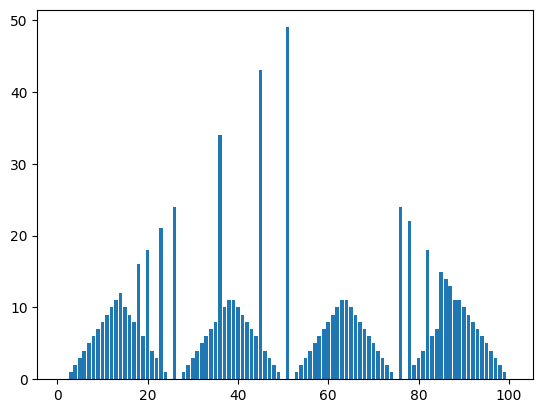

In [ ]:
plt.bar(torch.linspace(1, 100, steps= 100).numpy(), pi.numpy())
plt.show()

In [ ]:
# Our calculation - Brute force
per_sec = 1000000
per_min = 60 * per_sec
per_hou = 60 * per_min
per_day = 24 * per_hou
per_mon = 30 * per_day
per_year = 12 * per_mon
per_decade = 10 * per_year
per_century = 10 * per_decade
per_thousand = 10 * per_century
per_ten_thousand = 10 * per_thousand   # 10k years
per_hundrad_thousand = 10 * per_ten_thousand  # 100k years = 1 lack
per_million = 10 * per_hundrad_thousand      # 1m years

needed_time = int(3.215 * per_million)        # 3.215M years

# (10 ** 20 / 10 ** 6 ) / (365 * 24 * 3600)  -> chatGPT.5 calculation

# back - gammon states 100 quintillion = 10 ** 2 .
# By using value interation to compute single (just a single) sweap
# For 3.215 M years we can compute 99999360000000000000 ~ 99 quintillion states but actuall state is 100 quintillion states

# Monte Carlo Methods:
- Monte Carlo Methods are model free reinforcement learning methods. Where agent don't have to know the complete knowledge of environment.
- Since MC's are model free it learns from experience - sample of sequence of states, actions and rewards.
- *Monte Carlo* means any estimating methods that involves significant amount of random components.


## First-Visit Monte Carlo (Prediction):
- Prediction problems id about, where for any given arbitrary policy-π estimate value-function.

- *First-Visist MC* only estimates value-function at the completion (termination) of each episode: value of state get updated only once on first-visit MC within episode, if state-s visited (occurs) first time.

In [ ]:
GAMMA  = 0.9
episodes = 10000

counter = defaultdict(int)
# State-Value function
V = defaultdict(float)
# Returns for states
Returns = defaultdict(list)

In [ ]:
# Environment
env = gym.make("Blackjack-v1", natural = False, sab = False)

for _ in range(episodes):
    # What's going on in the evironment.
    observation, info = env.reset()

    # --------------------------------------------
    # Generate Episode: Trajectory under policy-pi
    # --------------------------------------------
    experience = []
    episode_over = False
    while not episode_over:
        current_step = []
        # Now it's just a static policy:
        # If Player cards sum is: sum >= 20 then a = 0 (stick) , sum < 20 then a is 1 (hit)
        current_step.append(observation)
        if observation[0] >= 20:
            action = env.action_space.sample(mask = np.array([1, 0], dtype = np.int8))
        else:
            action = env.action_space.sample(mask = np.array([0, 1], dtype = np.int8))
        current_step.append(action.item())
        # Dynamic changes: Next -> state, reward
        observation, reward, termination, truncation, info = env.step(action)
        current_step.append(reward)
        episode_over = termination or truncation

        # Append current step to experience
        experience.append(current_step)

    # -----------------------
    # First-Visit Monte Carlo
    # -----------------------
    first_visit = set()
    G = 0
    for t, (state_i, action_i, reward_i) in enumerate(experience[::-1], 1):
        G = reward_i + GAMMA * G
        if (state_i in set(s for s, _, _, in experience[:-t])) and (state_i not in first_visit):
            # Increase Counter: Number of times state_i visited across 'episodes'
            counter[state_i] += 1
            # For state_i: Append Goal to Returns
            Returns[state_i].append(G)
            # Update State-Value Function: value of state just a expected return
            V[state_i] = Returns[state_i]/counter[state_i]

            # Visit state_i first time
            first_visit.add(state_i)

In [ ]:
def first_vist_monte_carlo(Episodes: int, gamma: float = 1.0, incremental_update: bool = True, alpha: float| None = None):
    """
    Initiates Blackjack environment and build's state-value function using first visit Monte Carlo method.

    Args:
        Episodes: How many episodes do we need as experience.
        gamma: Blackjack is episodic task (MC only can be applied to episodic) so default to 1.
        incremental_update: Have to use incrmental update rule for estimating state-value function.
        alpha: Stepsize parameter for incremental update.
    Returns:
        V: State-Value function for Blackjack environment.
    """

    # Let's initiate blackjack environment
    env = gym.make("Blackjack-v1")
    # State Value function: How good it's for agent to be in specific state?
    V = torch.zeros(size = (22, 11, 2), device = DEVICE)
    if (not incremental_update and not alpha) or (incremental_update and not alpha):
        # Counter
        Counter = torch.zeros_like(V)
    # Returns
    # Returns = defaultdict(list)

    for _ in range(Episodes):
        # What's going on the env? Everytime new experience
        observation, info = env.reset()

        # --------------------------------------------------------------
        # Generate Episode (trajectory or experience): Agent - Environment interaction
        # --------------------------------------------------------------

        # Entire Trajectory
        experience = []
        episode_terminate = False
        while not episode_terminate:
            # Really have to make decision if cards_sum >= 12 else it would to obvious we(agent) go for hit(ask next card)

            current_step =  []
            current_step.append(observation)
            # Policy-pi: map's St to At. Consider pi, cards_sum >= 20 take a = 0(stick) & cards_sum < 20 take a = 1(hit)
            if observation[0] >= 20:
                action = env.action_space.sample(mask = np.array([1, 0], dtype = np.int8)).item()
            else:
                action = env.action_space.sample(mask = np.array([0, 1], dtype = np.int8)).item()
            current_step.append(action)

            # Dynamics transitions: Gives Reward Rt+1 and Next state St+1
            observation, reward , terminated, truncated, _ = env.step(action)
            current_step.append(reward)

            experience.append(current_step)
            episode_terminate = terminated or truncated

        # --------------
        # First-Visit MC
        # --------------
        first_visit = []
        G = 0
        for state_i, action_i, reward_i in experience[::-1]:
            G = reward_i + gamma * G
            if state_i not in first_visit:
                if (not incremental_update and not alpha) or (incremental_update and not alpha):
                    # Increase Counter: It would be across episodes
                    Counter[*state_i] += 1
                # Append Goal G to Over all Returns (Return is just a Goal. Return = Goal)
                # Returns[state_i].append(G)
                if incremental_update:
                    V[*state_i] = V[*state_i] + (1/Counter[*state_i]) if not alpha else alpha * (G - V[*state_i])
                else:
                    # Take empirical average for value of the state:
                    V[*state_i] += G   #sum(Returns[state_i])/Counter[*state_i]
                # Visit State first time
                first_visit.append(state_i)

    if not incremental_update:
        V = torch.where(Counter > 0.0, torch.div(V, Counter), V)
    return V

V = first_vist_monte_carlo(Episodes= 50000, incremental_update= False)

In [ ]:
def plot_value_function(V, usable_ace):
    fig = plt.figure(figsize = (10, 7))
    ax = fig.add_subplot(111, projection = '3d')
    X, Y = torch.meshgrid(
        torch.arange(1, 11, device = DEVICE),
        torch.arange(12, 22, device = DEVICE),
        indexing= "ij"
    )
    Z = V[12:, 1:, 1 if usable_ace else 0].transpose(1, 0)
    ax.plot_surface(X, Y, Z, cmap = 'viridis')
    ax.set_xlabel("Dealer Showing")
    ax.set_ylabel("Player Sum")
    ax.set_zlabel("Value")
    ax.set_title(label = f"Usable Ace = {usable_ace}")
    plt.show()

# plot_value_function(V, usable_ace= False)

## First-Visit Monte Carlo (Control):
- Here control with exploring starts. Exploring starts means make sure at first timestep of episode all (s, a) pair have non-zero probability of occuring chance.
- We though gym lib implicitly doing that for us.

In [ ]:
env = gym.make("Blackjack-v1")
Episodes = 30000
gamma = 1

# Policy: Starts with cards_sum >= 20 then a = 0 (stick) else a = 1 (hit)
pi = torch.ones(size= (22, 11, 2, 1), device = DEVICE)
pi[20:] = 0.0
# Action-Value function
Q = torch.zeros(size = (22, 11, 2, 2), device = DEVICE)    # (s, a) pair
# Counter: To tack how many times (s, a) pair visited across episodes
Counter = torch.zeros_like(Q, device= Q.device)

for _ in range(Episodes):
    # What's going on the env? Everytime new experience
    observation, info = env.reset()

    # --------------------------------------------------------------
    # Generate Episode (trajectory or experience): Agent - Environment interaction
    # --------------------------------------------------------------
    # Entire Trajectory
    experience = []
    episode_terminate = False
    while not episode_terminate:
        # Really have to make decision if cards_sum >= 12 else it would to obvious we(agent) go for hit(ask next card)

        current_step =  []
        current_step.append(observation)
        # Following policy-pi
        action_mask = np.array([0, 0], dtype = np.int8)
        action_mask[int(pi[*observation])] = 1
        action = env.action_space.sample(mask = action_mask).item()   # return tupe np convert to int
        current_step.append(action)
        # Dynamics transitions: Gives Reward Rt+1 and Next state St+1
        observation, reward , terminated, truncated, _ = env.step(action)
        current_step.append(reward)

        experience.append(current_step)
        episode_terminate = terminated or truncated

    # ------------------------
    # First-Visit MC - Control
    # -------------- ----------

    first_visit = []
    G = 0
    for state_i, action_i, reward_i in experience[::-1]:
        G = reward_i + gamma * G
        if (state_i, action_i) not in first_visit:
            # Increase Counter: It would be across episodes
            Counter[*state_i, action_i] += 1.0
            # Policy Evaluation
            Q[*state_i, action_i] = Q[*state_i, action_i] + (G - Q[*state_i, action_i]) / Counter[*state_i, action_i]
            # Policy Improvement: Act greedy with respect to action-value function
            pi[*state_i] = Q[*state_i].argmax(dim = 0).float()
            # Visit State first time
            first_visit.append((state_i, action_i))


## On-Policy First-Visit Monte Carlo Control (ϵ-soft policies,estimates π ≈ π*):


- On-Policy means behaviour and target policy are the same: We use ϵ-greedy is an instance of soft-policy (π(a|s) > 0)

In [ ]:
env = gym.make("Blackjack-v1")
# Algorithm parameters
Episodes = 100000
gamma = 1
epsilon = 1

# Action-Value
Q = torch.zeros(size = (22, 11, 2, 2), device = DEVICE)     # (s, a) pair value
# Counter
Counter = torch.zeros(size = (22, 11, 2, 2), device = DEVICE)  # (s, a) pair count

for ep in range(Episodes):
    # What's going on the env? Everytime new experience
    observation, info = env.reset()

    # --------------------------------------------------------------
    # Generate Episode (trajectory or experience): Agent - Environment interaction
    # --------------------------------------------------------------
    # Entire Trajectory
    experience = []
    episode_terminate = False
    while not episode_terminate:
        # Really have to make decision if cards_sum >= 12 else it would to obvious we(agent) go for hit(ask next card)

        current_step =  []
        current_step.append(observation)
        # Policy: epsilon-greedy policy
        if random.random() >= epsilon:
            action = Q[*observation].argmax(dim = 0).item()
        else:
            action = Q[*observation].softmax(dim = 0).multinomial(1).item()
        # action_mask = np.array([0, 0], dtype = np.int8)
        # action_mask[a] = 1
        # action = env.action_space.sample(mask = action_mask).item()   # return type np convert to int
        current_step.append(action)
        # Gives Reward Rt+1 and Next state St+1
        observation, reward , terminated, truncated, _ = env.step(action)
        current_step.append(reward)

        experience.append(current_step)
        episode_terminate = terminated or truncated

    # ------------------------
    # First-Visit MC - Control
    # -------------- ----------

    first_visit = []
    G = 0
    for state_i, action_i, reward_i in experience[::-1]:
        G = reward_i + gamma * G
        if (state_i, action_i) not in first_visit:
            # Increase Counter: It would be across episodes
            Counter[*state_i, action_i] += 1.0
            # Policy Evaluation
            Q[*state_i, action_i] = Q[*state_i, action_i] + (G - Q[*state_i, action_i]) / Counter[*state_i, action_i]
            # Visit State first time
            first_visit.append((state_i, action_i))

    epsilon = epsilon / (ep + 1)

# Temporal Difference Learning:
- Monte Carlo: Have to wait until die to update value-function 💀.
- Temporal Difference: Can update value-function immediatly, don't have to die at all 💭.  

## TD(0) Method:
- Special case of Temporal Difference Learning called $one\space step$-TD update method.
  
### Problem: Blackjack:
- Let's see how TD(0) handles blackjack compare to MC

In [ ]:
env = gym.make("Blackjack-v1")
# State-Value function:
V = torch.randn(size = (22, 11, 2), device = DEVICE)
# Step-size:
alpha = 0.05
gamma = 1
Episodes = 10000

for _ in range(Episodes):
    # Everytime environment has fresh start
    observation, info = env.reset()

    episode_terminate = False
    while not episode_terminate:

        # Let'consider pi fixed
        if observation[0] >= 20:
            action = env.action_space.sample(mask = np.array([1, 0], dtype = np.int8)).item()
        else:
            action = env.action_space.sample(mask = np.array([0, 1], dtype = np.int8)).item()

        # Take action and observe R, S'
        next_state, reward, terminated, truncated, _ = env.step(action)
        # Incremental update
        V[*observation] = V[*observation] + alpha * ((reward + gamma * V[*next_state] if next_state[0] <= 21 else 0.0) - V[*observation])

        observation = next_state
        episode_terminate = terminated or truncated

## Sarsa (on-policy TD Control) for estimating Q $\approx$ q*:
- Sarsa is on-policy TD Control method.
- Let's implement one-step Sarsa to solve Blackjack problem
- The update rule would be,

  $\hspace{5em} Q(S_{t}, A_{t}) \leftarrow Q(S_{t}, A_{t}) + \alpha (R_{t+1} + Q(S', A') - Q(S_{t}, A_{t}))$
- When we use $\alpha$ as step with TD, for stationary reward distripution like Blackjack it doesn't learn well. But when we use $\frac{1}{N}$ as step size it looks like it starting to learn.

In [ ]:
env = gym.make("Blackjack-v1")
# Action-Value Table
Q = torch.randn(size = (22, 11, 2, 2), device = DEVICE) * 0.02
# Q = torch.zeros(size = (22, 11, 2, 2), device = DEVICE) it doesn't learn at all
# Algorithm Hyper parameters
Episodes = 100000
# Step size
alpha = 0.01
# Counter = torch.zeros_like(Q, device = Q.device)
# Exploration Rate
epsilon = 0.1
# Discount factor - Gamma
gamma = 1

for _ in range(Episodes):
    # Fresh start of the environment
    state, info = env.reset()
    # Don't have to use explicit pi, act greedy or epsilon-greedy wrt to Q is enought
    # Sarsa starts with (S, A) pair
    if random.random() >= epsilon:
        action = Q[*state].argmax(dim = 0).item()
    else:
        action = Q[*state].softmax(dim = 0).multinomial(1).item()

    episode_terminate = False
    while not episode_terminate:
        # Counter[*state, action] += 1
        # Take action-A and observe R, S'
        next_state, reward, terminated, truncated, _ = env.step(action)

        if not (terminated or truncated):
            # Choose A' from S' using derived from Q (e.g, epsilon-greedy)
            if random.random() >= epsilon:
                next_action = Q[*next_state].argmax(dim = 0).item()
            else:
                next_action = Q[*next_state].softmax(dim = 0).multinomial(1).item()
        # Incremental update rule,
        Q[*state, action] += alpha * ((reward + gamma * (Q[*next_state, next_action]) if not (terminated or truncated) else 0.0) - Q[*state, action])

        if not (terminated or truncated):
            state, action = next_state, next_action
        episode_terminate = terminated or truncated

In [ ]:
# Extract greedy policy and state-value function
def extract_policy_and_value(Q, max:bool = False):
    policy = Q.argmax(dim = -1)
    V = Q.max(dim = -1).values if max else Q.sum(dim = -1)
    return policy, V

sarsa_policy, sarsa_v = extract_policy_and_value(Q, max = True)

In [ ]:
def plot_policy(policy, title):
    plt.figure(figsize = (10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(policy[12:, 1:, 1], origin = 'lower', extent= [1, 10, 12, 21], aspect='auto', vmin = 0, vmax = 1)
    plt.colorbar(ticks = [0, 1], label = "Action (0=stick, 1=hit)")
    plt.title(title + "(usable ace = True)")
    plt.xlabel("Dealer Showing"); plt.ylabel("Player Sum")
    plt.subplot(1, 2, 2)
    plt.imshow(policy[12:, 1:, 0], origin = 'lower', extent= [1, 10, 12, 21], aspect='auto', vmin = 0, vmax = 1)
    plt.colorbar(ticks = [0, 1], label = "Action (0=stick, 1=hit)")
    plt.title(title + "(usable ace = Flase)")
    plt.xlabel("Dealer Showing")
    plt.show()

def plot_value_function(V, usable_ace):
    fig = plt.figure(figsize = (10, 4))
    ax = fig.add_subplot(111, projection = '3d')
    X, Y = torch.meshgrid(
        torch.arange(1, 11, device = DEVICE),
        torch.arange(12, 22, device = DEVICE),
        indexing= "ij"
    )
    Z = V[12:, 1:, 1 if usable_ace else 0]
    ax.plot_surface(X, Y, Z, cmap = 'viridis')
    ax.set_xlabel("Dealer Showing")
    ax.set_ylabel("Player Sum")
    ax.set_zlabel("Value")
    ax.set_title(label = f"Usable Ace = {usable_ace}")
    plt.show()

# plot_value_function(V, usable_ace= False)
# plot_value_function(V = sarsa_v, usable_ace= False)
plot_policy(sarsa_policy, title= "Sarsa Learned Policy")
plot_value_function(V = sarsa_v, usable_ace= True)

## Q-Learning (off-policy TD control):
- Q-Learning is off-policy Temporal Difference Control method.
- Control methods are used to estimate optimal policy $\pi_{*}$.
- Off-policy methods are uses two policies:
    1. Behaviour Policy-$b$:
        - Generates data
        - Remains Explotrary (e.g, $\epsilon$-greedy)
    2. Target Policy-$\pi$:
        - Learns optimal behaviour
        - Greedy Policy.
- Update rule for Q-learning,
  
  $\hspace{5em} Q(S_{t}, A_{t}) \leftarrow Q(S_{t}, A_{t}) + \alpha \left( R_{t+1} + \gamma \max\limits_{a'} Q(S_{t+1}, a') - Q(S_{t}, A_{t})\right)$

In [ ]:
# Action-Value Function:
Q = torch.randn(size = (48, 4), device = DEVICE)
# Algorithm Parameters:
# Discount Factor
gamma = 1.0
# Constant Step Size
alpha = 0.5
# Exploration Rate
epsilon = 0.1
Episodes = 2000

start_time = time.time()
for e in range(Episodes):

    state, info = env.reset()
    episode_terminated = False
    while not episode_terminated:
        # Behaviour Policy: epsilon-greedy
        if random.random() >= epsilon:
            action = Q[state].argmax(dim = 0).item()
        else:
            action = Q[state].softmax(dim = 0).multinomial(1).item()

        # Take action A, observe R, S'
        next_state, reward, terminated, truncated, _ = env.step(action)
        # Incremental Update rule: Bootstrapping remaning reward by Q(S', A') greedily
        Q[state, action] += alpha * ((reward + gamma * (Q[next_state].max(dim = 0).values if next_state <= 47 else 0.0))- Q[state, action])

        state = next_state
        episode_terminated = terminated or truncated

    if (e + 1) % 200 == 0 :
        print(f"Episode {e + 1}: Completed !, Training time: {(time.time() - start_time)/60} M")

In [ ]:
# function to get greedy path following Q (stop at goal or cliff or max steps)
def greedy_path_from_Q(Q, env, max_steps=100):
    s, _ = env.reset()
    path = [s]
    fallen = False
    for _ in range(max_steps):
        a = Q[s].argmax(dim = 0).item()
        s_next, rwd, done, truncated, _ = env.step(a)
        path.append(s_next)
        if done:
            fallen = True if rwd == -100 else False
            break
        s = s_next

    # Convert Path int representation to grid position
    grid_ind = {r * 12 + c: (r, c) for r in range(0, 4) for c in range(0, 12)}
    path = [grid_ind[p] for p in path]

    return path, fallen

In [ ]:
q_path, q_fallen = greedy_path_from_Q(Q, env)
q_policy = Q.argmax(dim = -1).reshape(4, 12)

In [ ]:
# Plotting arrow grids
action_to_vec = {0: (0, 1), 1: (1, 0), 2: (0, -1), 3: (-1, 0)}
def plot_policy_arrows(policy, Q, path, title):
    rows, cols = 4, 12
    goal = (rows - 1, cols - 1)
    cliff = {(rows - 1, c) for c in range(1, cols - 1)}
    X, Y = np.meshgrid(np.arange(cols), np.arange(rows))
    U = np.zeros_like(X, dtype=float)
    V = np.zeros_like(Y, dtype=float)
    for r in range(rows):
        for c in range(cols):
            if (r, c) in cliff or (r, c) == goal:
                U[r, c] = 0
                V[r, c] = 0
            else:
                a = int(policy[r, c])
                dc, dr = action_to_vec[a]  # note: dc horizontal, dr vertical (up positive)
                U[r, c] = dc
                V[r, c] = dr

    plt.figure(figsize=(6,3.5))
    plt.title(title)
    # show grid background: cliff, start, goal
    grid = np.zeros((rows, cols, 3))
    # color mappings: normal=light, cliff=dark, start=green, goal=yellow
    for r in range(rows):
        for c in range(cols):
            if (r, c) in cliff:
                grid[r, c] = np.array([0.2, 0.0, 0.3])  # dark
            else:
                grid[r, c] = np.array([0.7, 0.9, 0.9])  # light
    sr, sc = (3, 0); grid[sr, sc] = np.array([0.2, 0.8, 0.2])
    gr, gc = (3, 11); grid[gr, gc] = np.array([0.95, 0.9, 0.2])
    # show image with origin='upper' but flip Y so arrows match grid orientation
    plt.imshow(grid, origin='upper', extent=[0, cols, rows, 0])
    # compute arrow positions - align with image coordinates: x=c+0.5, y=r+0.5 (with origin upper)
    xs = []
    ys = []
    us = []
    vs = []
    for r in range(rows):
        for c in range(cols):
            # skip cliff and goal for arrows
            if (r, c) in cliff or (r, c) == goal:
                continue
            xs.append(c + 0.5)
            ys.append(r + 0.5)
            # we must convert U,V to image coordinates (y increases downward)
            a = int(policy[r, c])
            # original action_to_vec defined up as (0,1); for image coords (origin upper) we invert vertical
            dc, dr = action_to_vec[a]
            us.append(dc)
            vs.append(-dr)
    plt.quiver(xs, ys, us, vs, angles='xy', scale_units='xy', scale=1, color='k', width=0.007)
    # overlay greedy path
    px = [c + 0.5 for (r, c) in path]
    py = [r + 0.5 for (r, c) in path]
    plt.plot(px, py, marker='o', color='orange', linewidth=2)
    plt.scatter([sc + 0.5], [sr + 0.5], color='black', s=50)  # start
    plt.scatter([gc + 0.5], [gr + 0.5], color='red', s=50)    # goal
    plt.xlim(0, cols)
    plt.ylim(rows, 0)
    plt.xticks(np.arange(0.5, cols + 0.5, 1), np.arange(0, cols, 1))
    plt.yticks(np.arange(0.5, rows + 0.5, 1), np.arange(0, rows, 1))
    plt.grid(False)
    plt.show()


# n-step Bootstrapping:
- n-step bootstrapping is spectrem of algorithms between Monte Carlo and TD(0):
    - $n \rightarrow \infty$ then it's Monte Carlo
    - $n \rightarrow 1$ then it's TD(0)
- n-step algorithms uses $n-step\space return$ as target and bootstraps (estimates) remaing rewards using value-functions.

## off-policy $n-step\space Sarsa$ for estimating $Q\space \approx q_{*}\space or q_{\pi}$:
- Sarsa extented to use n-step return with importance sampling ratio.
- The update rule would be,
  
  $\hspace{5em} Q_{t+n}(S_{t}, A_{t}) \leftarrow Q_{t+n-1} + \alpha p_{t+1: t+n} \left(G_{t: t+n} - Q_{t+n-1}(S_{t}, A_{t}) \right)$

In [ ]:
# Action-Value Function:
Q = torch.randn(size = (48, 4), device = DEVICE)
# Algorithm Parameters:
# Discount Factor
gamma = 1.0
# Constant Step Size
alpha = 0.05
# n-step
n = 3
# Exploration Rate
epsilon = 0.15
Episodes = 20

for ep in range(Episodes):

    t, T = 0, float("inf")
    # For storing S, A, R to compute importance sampling ratio and n-step return
    n_step_history = defaultdict(dict)
    # Sarsa starts with S, A pair
    state, _ = env.reset()
    n_step_history[t] = {"S": state}
    # Behaviour Policy: epsilon-greedy
    if random.random() >= epsilon:
        action = Q[state].argmax(dim = 0).item()
        n_step_history[t].update({"A": action})
        n_step_history[t].update({"A_prop": 1.0})
    else:
        probs = Q[state].softmax(dim = 0)
        action = probs.multinomial(1).item()
        n_step_history[t].update({"A": action})
        n_step_history[t].update({"A_prop": probs[action].item()})

    while t < T:
        # Take action and observe and store R', S'
        next_state, reward, terminated, truncated, _ = env.step(action)
        n_step_history[t+1] = {"S": next_state, "R": reward}
        if terminated or truncated:
            T = t + 1
        else:
            # Behaviour Policy: epsilon-greedy
            if random.random() >= epsilon:
                action = Q[next_state].argmax(dim = 0).item()
                n_step_history[t+1].update({"A": action})
                n_step_history[t+1].update({"A_prop": 1.0})
            else:
                probs = Q[next_state].softmax(dim = 0)
                action = probs.multinomial(1).item()
                n_step_history[t+1].update({"A": action})
                n_step_history[t+1].update({"A_prop": probs[action].item()})

        r = t - n + 1       # Who's estimation being updated
        if r >= 0:
            # Importance Sampling ratio: This ain't efficient way to compute
            ratio = 1.0
            for i in range(r + 1, min(r + n, T - 1)):
                ratio *= 1.0 / n_step_history[i]['A_prop']
            # n-step return: Unbiased
            G = 0.0
            for i in range(r + 1, min(r + n, T)):
                G += gamma ** (i-r-1) * n_step_history[i]['R']
            # Now making return biased by bootstrapping, if possible
            G += (gamma ** n) * Q[n_step_history[r+n]['S'], n_step_history[r+n]["A"]] if (r + n) < T else 0.0
            # Incremental Update
            Q[n_step_history[r]['S'], n_step_history[r]['A']] += alpha * ratio *(G - Q[n_step_history[r]['S'], n_step_history[r]['A']] )

            # If we updated then it's history ain't going to help for others
            del n_step_history[r]

        t += 1

In [ ]:
n_step_path, n_step_fallen = greedy_path_from_Q(Q, env)
n_step_policy = Q.argmax(dim = -1).reshape(4, 12)